# Plaquette and clover energy under Wilson gradient flow

Reference L24 $U$, Flow 1 output and Flow 2 output are shown in separate panels.
Each field starts at $t=0$: double-precision Wilson flow, RK3 step 0.02,
$0\le t/a^2\le5$.

Plaquette uses the original six paired test configurations (IDs 4, 59, 119, 179, 239, 299).
Clover energy uses all 60 paired test configurations (IDs 4, 9, …, 299).
Each configuration has its own color, consistent across panels and both figures.
No ensemble-mean curve is added.
Axes are shared within each figure to allow direct comparison.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p/'pyproject.toml').exists())
RESULTS = ROOT/'presentation/results/gradient_flow_diagnostics'
stages = ['reference', 'flow1', 'flow2']
labels = ['Reference L24', 'Flow 1', 'Flow 2']
test_ids = np.arange(4, 300, 5)
sample_ids = np.array([4, 59, 119, 179, 239, 299])
norm = Normalize(test_ids[0], test_ids[-1])
colors = plt.get_cmap('turbo')(norm(test_ids))
sample_colors = plt.get_cmap('turbo')(norm(sample_ids))
sample = {stage: dict(np.load(RESULTS/stage/'measurements.npz')) for stage in stages}
full = dict(np.load(RESULTS/'ensemble_clover.npz'))
plt.rcParams.update({'figure.dpi': 125, 'axes.grid': True, 'grid.alpha': .18})

np.testing.assert_array_equal(full['config_indices'], test_ids)
for stage in stages:
    metadata = json.loads((RESULTS/stage/'run.json').read_text())
    assert metadata['complete']
    np.testing.assert_array_equal(sample[stage]['config_indices'], sample_ids)
    assert sample[stage]['plaquette'].shape == (6, 59, 3)
    assert full[f'{stage}_energy'].shape == (60, 51, 3)
    assert np.isfinite(sample[stage]['plaquette']).all()
    assert np.isfinite(full[f'{stage}_energy']).all()


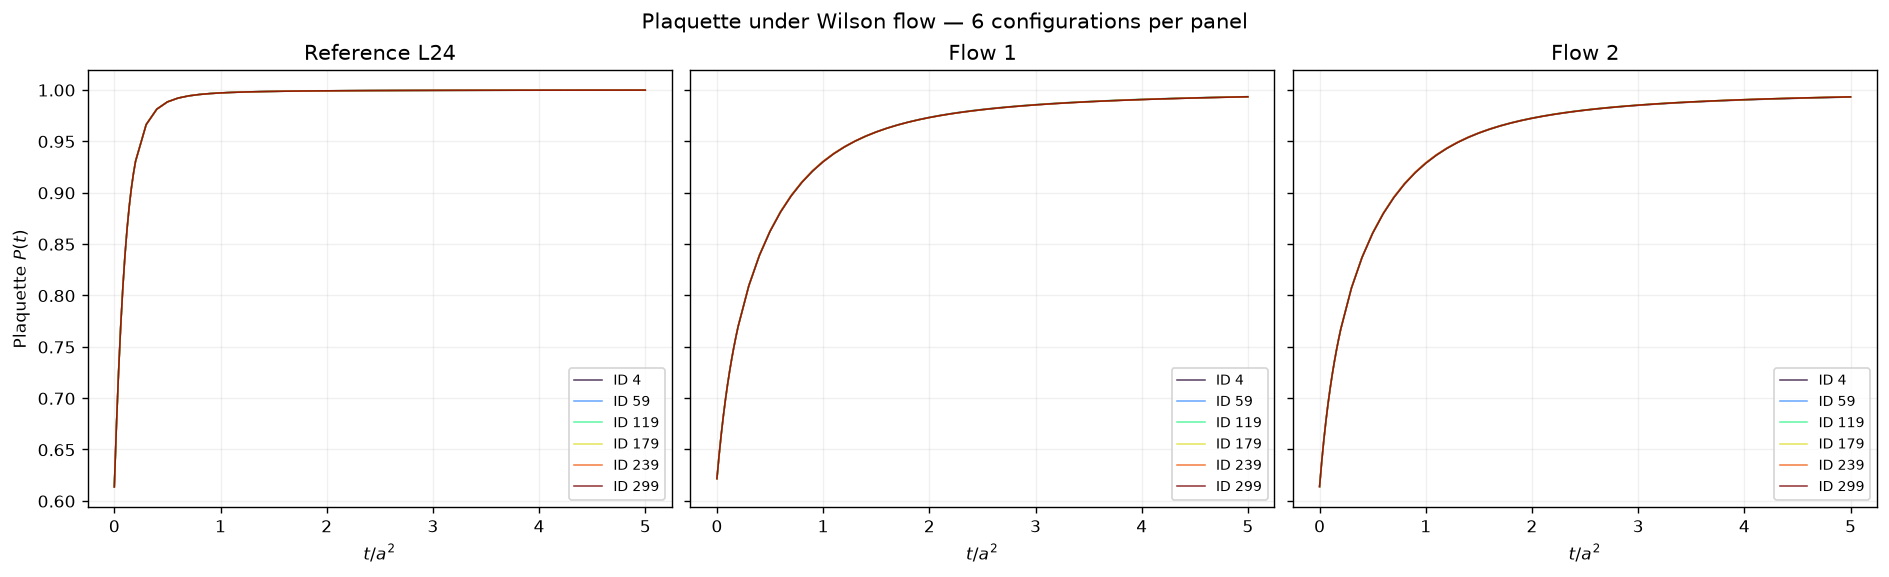

In [2]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True, constrained_layout=True)
for ax, stage, label in zip(axes, stages, labels):
    times = sample[stage]['flow_times']
    values = sample[stage]['plaquette'][:, :, 0]
    for source_id, curve, color in zip(sample_ids, values, sample_colors):
        ax.plot(times, curve, color=color, alpha=.8, linewidth=.9, label=f'ID {source_id}')
    assert len(ax.lines) == 6
    ax.set(title=label, xlabel=r'$t/a^2$')
    ax.legend(fontsize=8)
axes[0].set_ylabel(r'Plaquette $P(t)$')
figure.suptitle('Plaquette under Wilson flow — 6 configurations per panel')
figure.savefig(RESULTS/'gradient_flow_plaquette.png', dpi=180, bbox_inches='tight')
figure.savefig(RESULTS/'gradient_flow_plaquette.pdf', bbox_inches='tight')
plt.show()


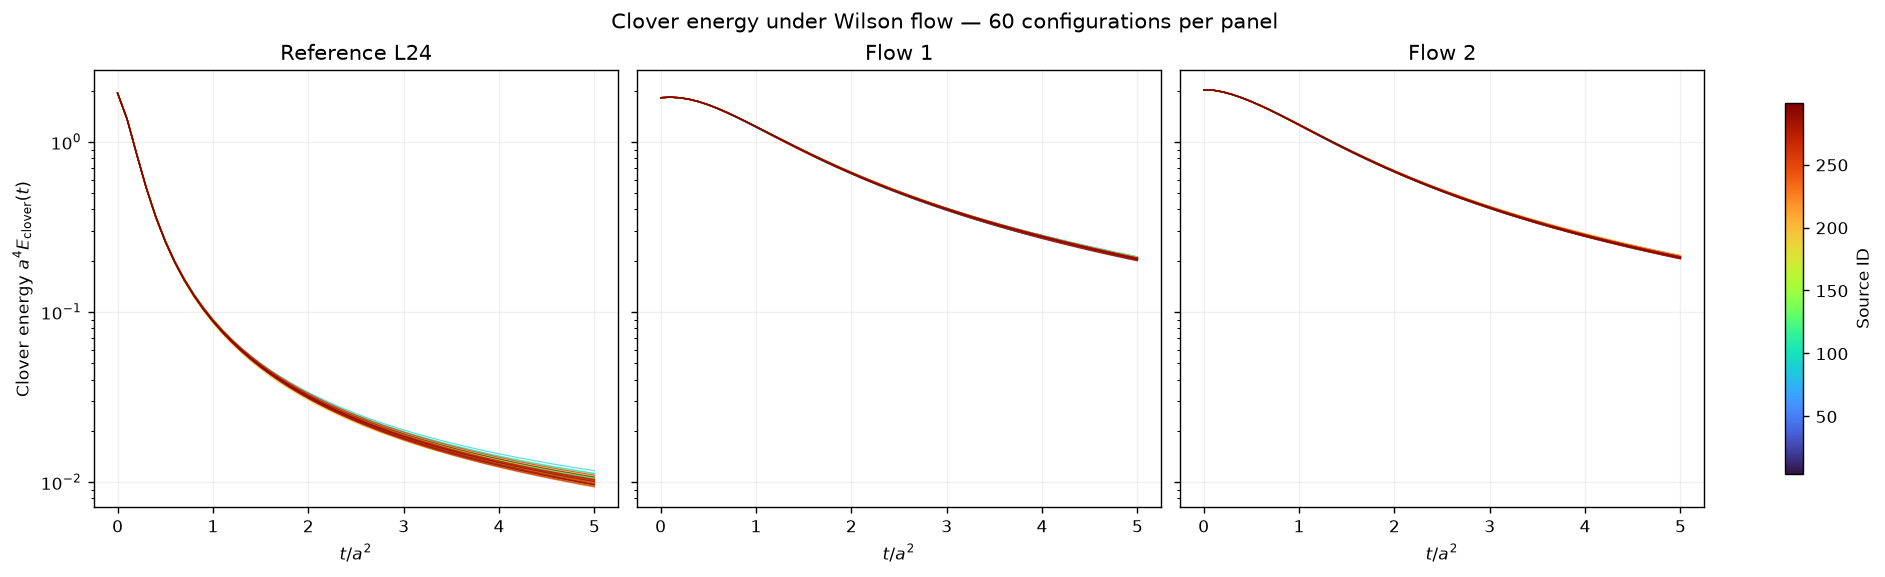

In [3]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True, constrained_layout=True)
for ax, stage, label in zip(axes, stages, labels):
    times = full['flow_times']
    values = full[f'{stage}_energy'][:, :, 0]
    for curve, color in zip(values, colors):
        ax.plot(times, curve, color=color, alpha=.7, linewidth=.7)
    assert len(ax.lines) == 60
    ax.set(title=label, xlabel=r'$t/a^2$', yscale='log')
axes[0].set_ylabel(r'Clover energy $a^4 E_{\mathrm{clover}}(t)$')
figure.suptitle('Clover energy under Wilson flow — 60 configurations per panel')
figure.colorbar(ScalarMappable(norm=norm, cmap='turbo'), ax=axes, label='Source ID', shrink=.85)
figure.savefig(RESULTS/'gradient_flow_clover.png', dpi=180, bbox_inches='tight')
figure.savefig(RESULTS/'gradient_flow_clover.pdf', bbox_inches='tight')
plt.show()


The 60-configuration clover cache provenance is recorded in [ensemble_clover_sources.json](results/gradient_flow_diagnostics/ensemble_clover_sources.json).
Six-source numerical checks are saved in [validation.json](results/gradient_flow_diagnostics/validation.json)
and [independent_clover.json](results/gradient_flow_diagnostics/independent_clover.json).
The exact-identity QUDA flow control produced NaNs; the near-identity control and all measured ensemble histories are finite.

Regenerate these two figures from the saved measurements:

```bash
.venv/bin/python scripts/upsample/make_gradient_flow_notebook.py
```
